# CC1 – Réseaux de neurones sur **Housing.csv**
**Partie 1 : `sklearn` – `MLPRegressor`**  |  **Partie 2 : `TensorFlow` – `GradientTape`**  |  **Partie 3 : `Keras` – `Sequential`**  |  **Partie 4 : Comparaison**

> Problème de **régression** : on prédit le prix (`price`). Les performances sont mesurées avec R², RMSE et MAE.

**Données utilisées** : `Housing.csv` (545 lignes, 13 colonnes).


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import os, warnings; warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid", palette="Set2")

### Dépendances
Si TensorFlow n'est pas installé dans votre environnement, installez-le avant d'exécuter les parties GradientTape et Keras : `pip install tensorflow`.

## 1. Chargement des données

In [5]:
# Chargement de Housing.csv
DATA_PATH = "Housing.csv"

if not os.path.exists(DATA_PATH):
    # Permet aussi l'exécution si le notebook est lancé depuis /mnt/data
    DATA_PATH = "Housing.csv"

df = pd.read_csv(DATA_PATH)

print("Fichier chargé :", DATA_PATH)
print("Dimensions :", df.shape)
display(df.head())


Fichier chargé : Housing.csv
Dimensions : (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## 2. Exploration et nettoyage

In [7]:
# Types de variables et statistiques de la cible
target = "price"

num_cols = df.select_dtypes(include="number").columns.drop(target).tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print(f"{len(num_cols)} variables numériques :", num_cols)
print(f"{len(cat_cols)} variables catégorielles :", cat_cols)
display(df[target].describe())


5 variables numériques : ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
7 variables catégorielles : ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


count    5.450000e+02
mean     4.766729e+06
std      1.870440e+06
min      1.750000e+06
25%      3.430000e+06
50%      4.340000e+06
75%      5.740000e+06
max      1.330000e+07
Name: price, dtype: float64

In [8]:
# Valeurs manquantes
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]

if len(miss):
    plt.figure(figsize=(10, 5))
    sns.barplot(x=miss.values, y=miss.index)
    plt.xlabel("% de valeurs manquantes")
    plt.title("Valeurs manquantes par variable")
    plt.tight_layout()
    plt.show()
else:
    print("Aucune valeur manquante dans la base.")


Aucune valeur manquante dans la base.


In [9]:
# Nettoyage
to_drop = miss[miss > 50].index.tolist()
print("Colonnes supprimées (>50 % de valeurs manquantes) :", to_drop)
df = df.drop(columns=to_drop)

print("Doublons :", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Mise à jour des listes de variables après nettoyage
num_cols = [c for c in num_cols if c in df.columns]
cat_cols = [c for c in cat_cols if c in df.columns]

print("Dimensions finales :", df.shape)
display(df.head())


Colonnes supprimées (>50 % de valeurs manquantes) : []
Doublons : 0
Dimensions finales : (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## 3. Visualisation

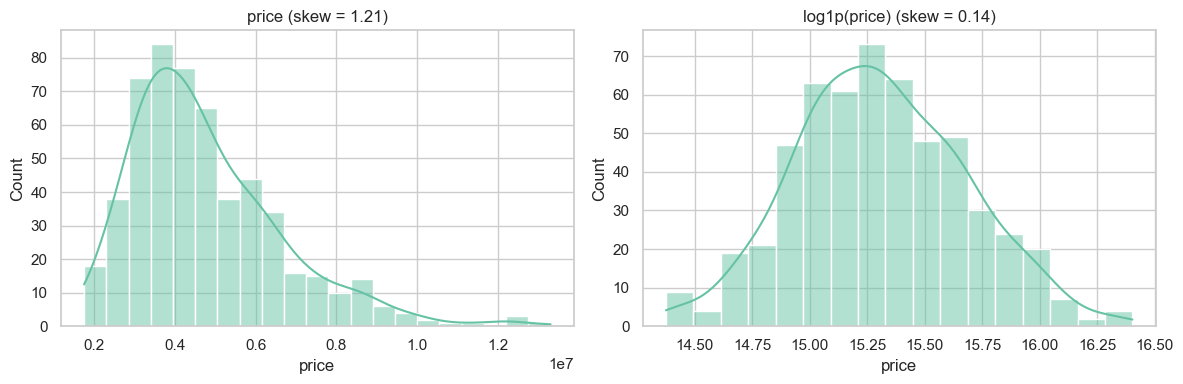

In [11]:
# Distribution du prix
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], kde=True, ax=ax[0])
ax[0].set_title(f"price (skew = {df['price'].skew():.2f})")

sns.histplot(np.log1p(df["price"]), kde=True, ax=ax[1])
ax[1].set_title(f"log1p(price) (skew = {np.log1p(df['price']).skew():.2f})")

plt.tight_layout()
plt.show()


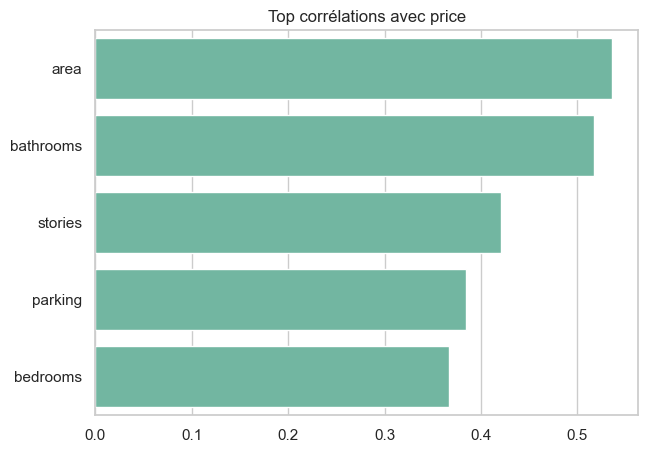

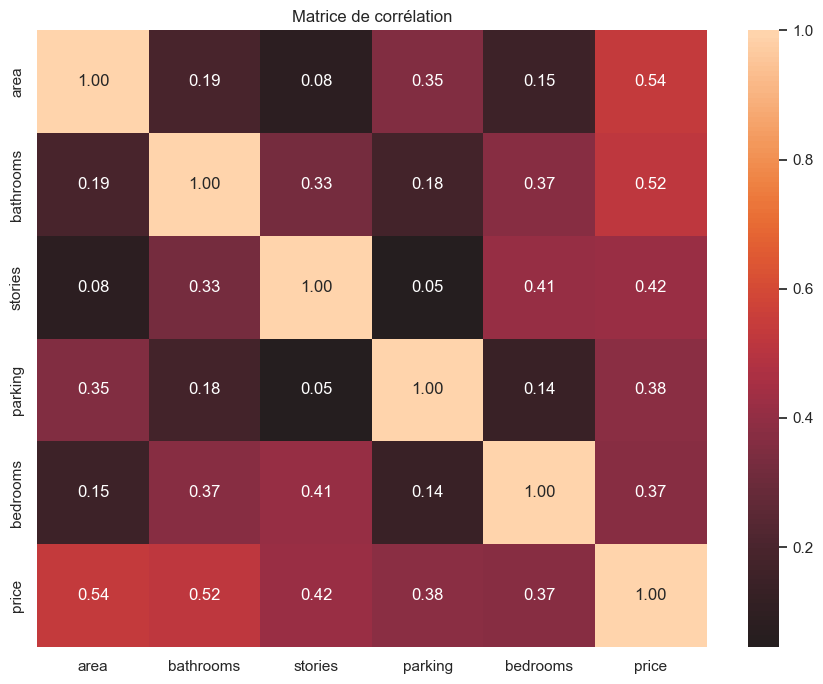

In [12]:
# Corrélations des variables numériques avec le prix
corr = df[num_cols + ["price"]].corr()["price"].drop("price").sort_values(ascending=False)
top = corr.abs().sort_values(ascending=False).head(min(10, len(corr))).index.tolist()

plt.figure(figsize=(7, 5))
sns.barplot(x=corr[top].values, y=top)
plt.title("Top corrélations avec price")
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(df[top + ["price"]].corr(), annot=True, fmt=".2f", center=0)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()


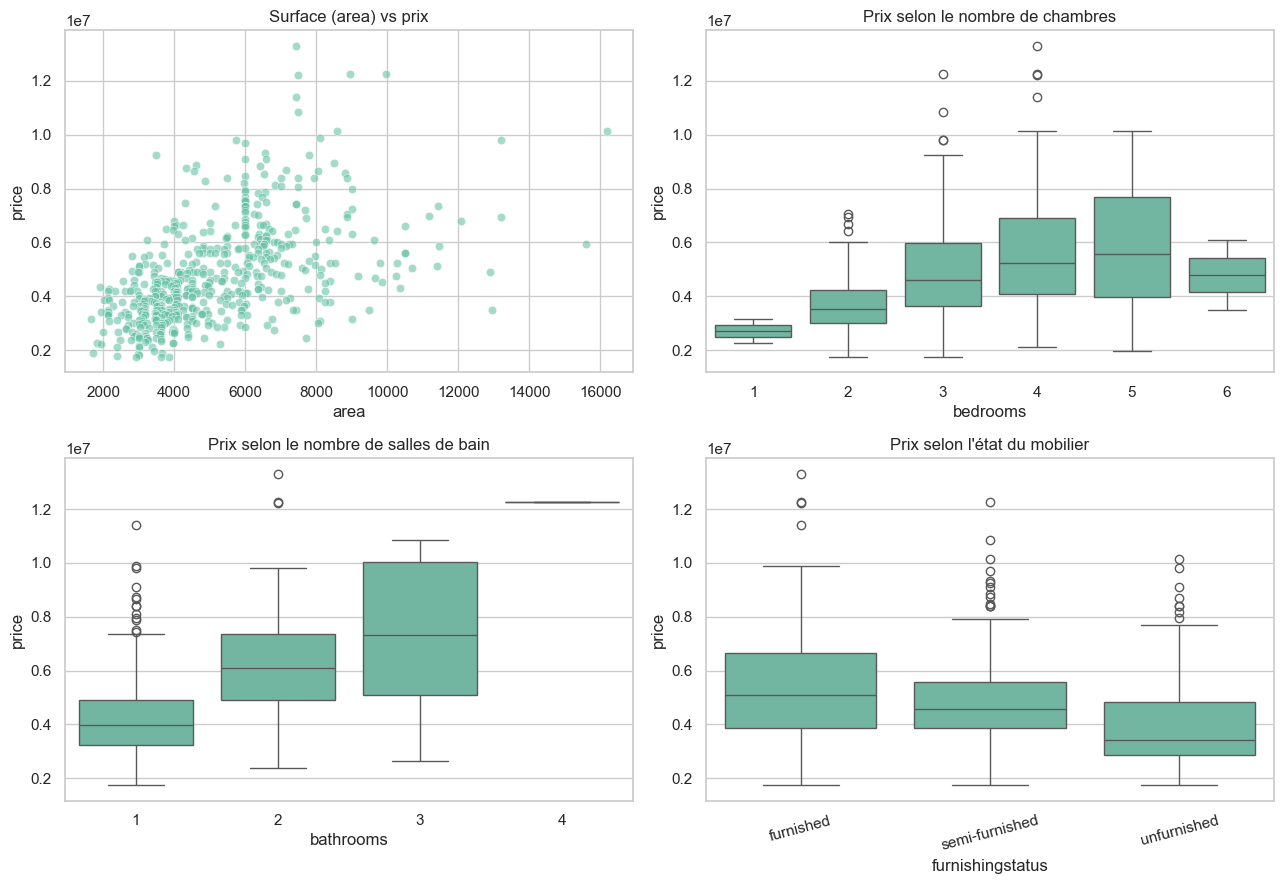

In [13]:
# Quelques relations avec le prix
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

sns.scatterplot(data=df, x="area", y="price", alpha=.6, ax=ax[0,0])
ax[0,0].set_title("Surface (area) vs prix")

sns.boxplot(data=df, x="bedrooms", y="price", ax=ax[0,1])
ax[0,1].set_title("Prix selon le nombre de chambres")

sns.boxplot(data=df, x="bathrooms", y="price", ax=ax[1,0])
ax[1,0].set_title("Prix selon le nombre de salles de bain")

sns.boxplot(data=df, x="furnishingstatus", y="price", ax=ax[1,1])
ax[1,1].set_title("Prix selon l'état du mobilier")
ax[1,1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


## 4. Prétraitement
- **Cible** : `log1p(price)` pour réduire l'asymétrie du prix, puis **standardisation** (moyenne 0, écart-type 1) pour que les réseaux n'aient pas à apprendre un décalage de ~15 en sortie (sans cela, avec L2 + Dropout + early stopping, GradientTape et Keras donnent un R² négatif).
- **Variables numériques** : imputation médiane + standardisation.
- **Variables catégorielles** : imputation par la modalité la plus fréquente + One-Hot Encoding.
- Le `ColumnTransformer` est ajusté uniquement sur le train pour éviter la fuite de données.


In [15]:
X = df.drop(columns=target)
y = np.log1p(df[target])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), cat_cols),
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

# Standardisation de la cible (ajustée sur le train uniquement)
y_scaler = StandardScaler()
y_train_s = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()

def to_log(pred_scaled):
    """Retour à l'échelle log1p(price) depuis la cible standardisée."""
    return y_scaler.inverse_transform(np.asarray(pred_scaled).reshape(-1, 1)).ravel()

print("Shape après prétraitement :", X_train_p.shape, X_test_p.shape)
print("NaN restants train :", np.isnan(X_train_p).sum())
print("NaN restants test  :", np.isnan(X_test_p).sum())


Shape après prétraitement : (436, 20) (109, 20)
NaN restants train : 0
NaN restants test  : 0


In [16]:
def evaluate(name, y_true_log, y_pred_log):
    """Métriques sur l'échelle réelle du prix + R² sur l'échelle log."""
    yt, yp = np.expm1(y_true_log), np.expm1(y_pred_log)
    return {
        "Modèle": name,
        "R² (log)": r2_score(y_true_log, y_pred_log),
        "R² (prix)": r2_score(yt, yp),
        "RMSE": np.sqrt(mean_squared_error(yt, yp)),
        "MAE": mean_absolute_error(yt, yp)
    }

def plot_pred(y_true_log, y_pred_log, title):
    yt, yp = np.expm1(y_true_log), np.expm1(y_pred_log)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

    ax[0].scatter(yt, yp, alpha=.5)
    lim = [yt.min(), yt.max()]
    ax[0].plot(lim, lim, "r--")
    ax[0].set_xlabel("Prix réel")
    ax[0].set_ylabel("Prix prédit")
    ax[0].set_title(title)

    sns.histplot(yt - yp, kde=True, ax=ax[1])
    ax[1].set_title("Résidus (réel − prédit)")

    plt.tight_layout()
    plt.show()


## 5. sklearn – `MLPRegressor`

In [18]:
mlp = MLPRegressor(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=1e-2,
    learning_rate_init=1e-3,
    max_iter=1000,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=30,
    random_state=SEED
)

mlp.fit(X_train_p, y_train_s)

pred_mlp = to_log(mlp.predict(X_test_p))
res_mlp = evaluate("sklearn MLPRegressor", y_test, pred_mlp)
print(pd.Series(res_mlp))


Modèle       sklearn MLPRegressor
R² (log)                 0.648744
R² (prix)                 0.63805
RMSE               1352591.544503
MAE                1019044.968885
dtype: object


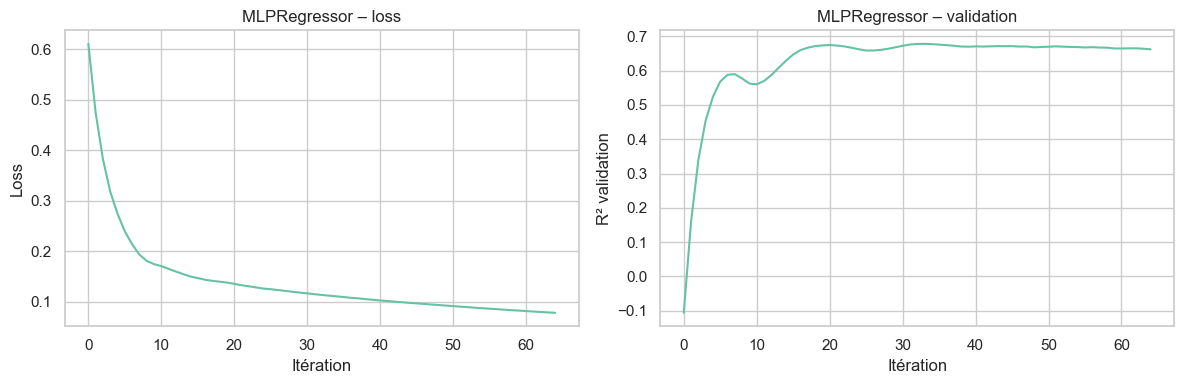

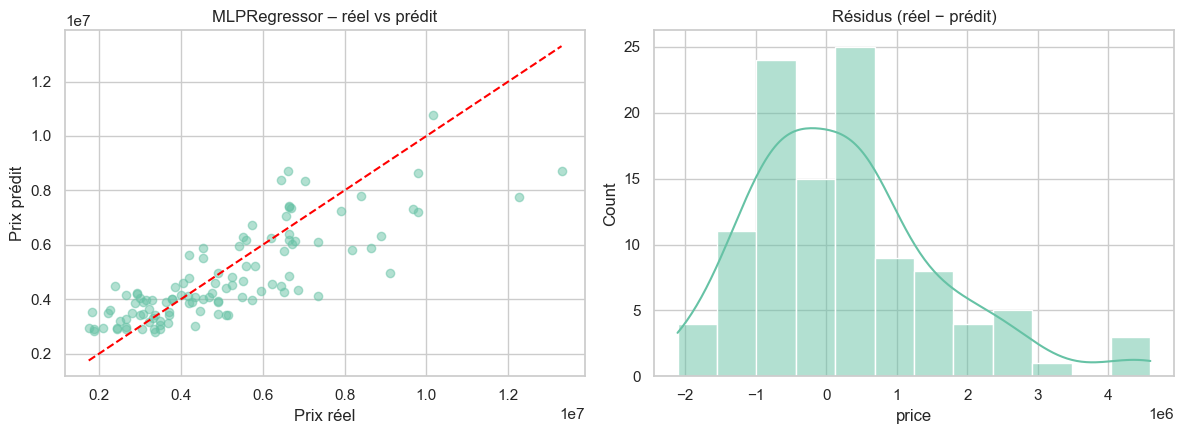

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(mlp.loss_curve_)
ax[0].set_xlabel("Itération")
ax[0].set_ylabel("Loss")
ax[0].set_title("MLPRegressor – loss")

if hasattr(mlp, "validation_scores_"):
    ax[1].plot(mlp.validation_scores_)
    ax[1].set_xlabel("Itération")
    ax[1].set_ylabel("R² validation")
    ax[1].set_title("MLPRegressor – validation")

plt.tight_layout()
plt.show()

plot_pred(y_test, pred_mlp, "MLPRegressor – réel vs prédit")


## 6. TensorFlow – `tf.GradientTape`
Boucle d'entraînement écrite à la main : poids `tf.Variable`, forward, perte MSE (+ régularisation L2), `Dropout` en entraînement uniquement, gradients via `tf.GradientTape`, optimiseur Adam et early stopping manuel.

In [21]:
# Jeu de validation (15 % du train)
Xtr, Xval, ytr, yval = train_test_split(
    X_train_p, y_train_s, test_size=0.15, random_state=SEED
)

Xtr = tf.constant(Xtr, tf.float32)
Xval = tf.constant(Xval, tf.float32)
ytr = tf.constant(ytr.reshape(-1, 1), tf.float32)
yval = tf.constant(yval.reshape(-1, 1), tf.float32)

def init_params(sizes):
    init = tf.keras.initializers.HeNormal(seed=SEED)
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        params += [
            tf.Variable(init((n_in, n_out))),
            tf.Variable(tf.zeros((n_out,)))
        ]
    return params

def forward(x, params, training=False):
    W1, b1, W2, b2, W3, b3 = params
    h1 = tf.nn.relu(x @ W1 + b1)
    if training:
        h1 = tf.nn.dropout(h1, rate=0.3)

    h2 = tf.nn.relu(h1 @ W2 + b2)
    if training:
        h2 = tf.nn.dropout(h2, rate=0.2)

    return h2 @ W3 + b3

L2 = 1e-3

def loss_fn(y_true, y_pred, params=None):
    mse = tf.reduce_mean(tf.square(y_true - y_pred))
    if params is None:
        return mse
    l2_penalty = tf.add_n([
        tf.reduce_sum(tf.square(w)) for w in params[0::2]
    ])
    return mse + L2 * l2_penalty

params_gt = init_params([X_train_p.shape[1], 128, 64, 1])
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

@tf.function
def train_step(xb, yb):
    with tf.GradientTape() as tape:
        pred = forward(xb, params_gt, training=True)
        loss = loss_fn(yb, pred, params_gt)

    grads = tape.gradient(loss, params_gt)
    optimizer.apply_gradients(zip(grads, params_gt))
    return loss


Early stopping à l'epoch 63
Epochs effectuées : 63


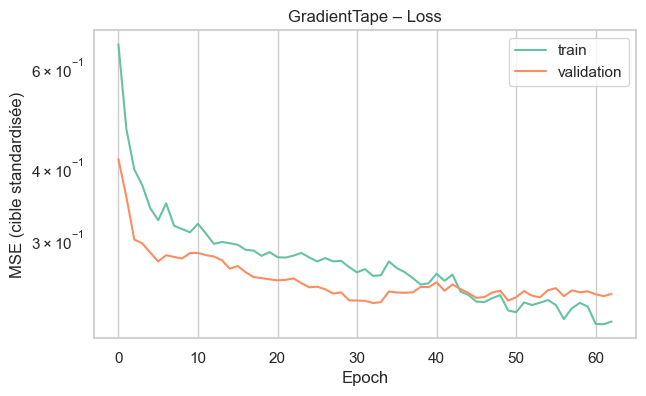

In [22]:
EPOCHS, BATCH, PATIENCE = 500, 32, 30
train_ds = tf.data.Dataset.from_tensor_slices((Xtr, ytr)).shuffle(
    len(Xtr), seed=SEED
).batch(BATCH)

hist_gt = {"loss": [], "val_loss": []}
best_val, wait, best_weights = np.inf, 0, None

for epoch in range(EPOCHS):
    for xb, yb in train_ds:
        train_step(xb, yb)

    train_loss = float(loss_fn(ytr, forward(Xtr, params_gt)))
    val_loss = float(loss_fn(yval, forward(Xval, params_gt)))

    hist_gt["loss"].append(train_loss)
    hist_gt["val_loss"].append(val_loss)

    if val_loss < best_val - 1e-5:
        best_val = val_loss
        wait = 0
        best_weights = [p.numpy() for p in params_gt]
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping à l'epoch {epoch + 1}")
            break

for p, w in zip(params_gt, best_weights):
    p.assign(w)

print("Epochs effectuées :", len(hist_gt["loss"]))

plt.figure(figsize=(7, 4))
plt.plot(hist_gt["loss"], label="train")
plt.plot(hist_gt["val_loss"], label="validation")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE (cible standardisée)")
plt.legend()
plt.title("GradientTape – Loss")
plt.show()


Modèle       TensorFlow GradientTape
R² (log)                    0.592291
R² (prix)                    0.57144
RMSE                  1471797.107377
MAE                   1081276.672018
dtype: object


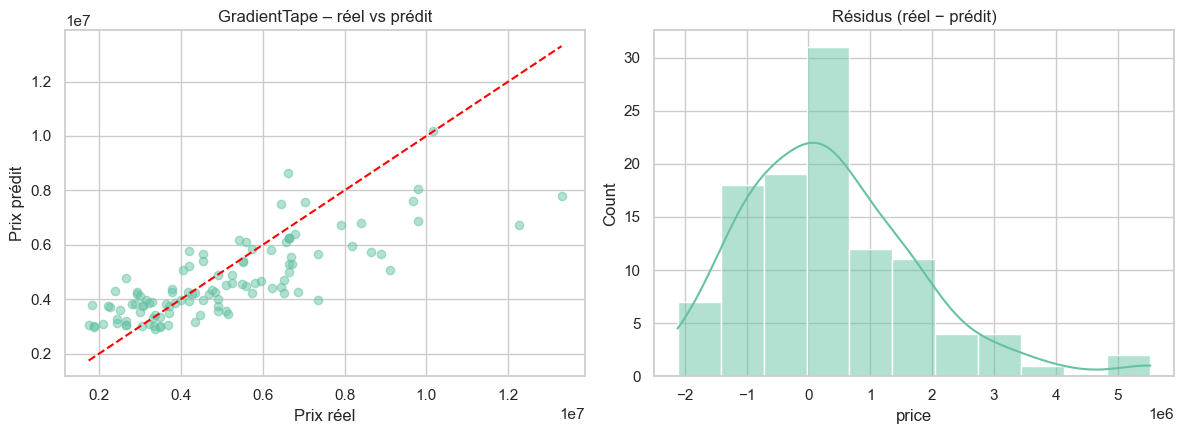

In [23]:
pred_gt = to_log(forward(tf.constant(X_test_p, tf.float32), params_gt).numpy().ravel())
res_gt = evaluate("TensorFlow GradientTape", y_test, pred_gt)
print(pd.Series(res_gt))
plot_pred(y_test, pred_gt, "GradientTape – réel vs prédit")

## 7. Keras – `Sequential`

In [25]:
n_features = X_train_p.shape[1]
model = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(128, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-3)),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-3)),
    layers.Dropout(0.2),
    layers.Dense(1),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │           2,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,009 (43.00 KB)

 Trainable params: 11,009 (43.00 KB)

 Non-trainable params: 0 (0.00 B)

Epochs effectuées : 77


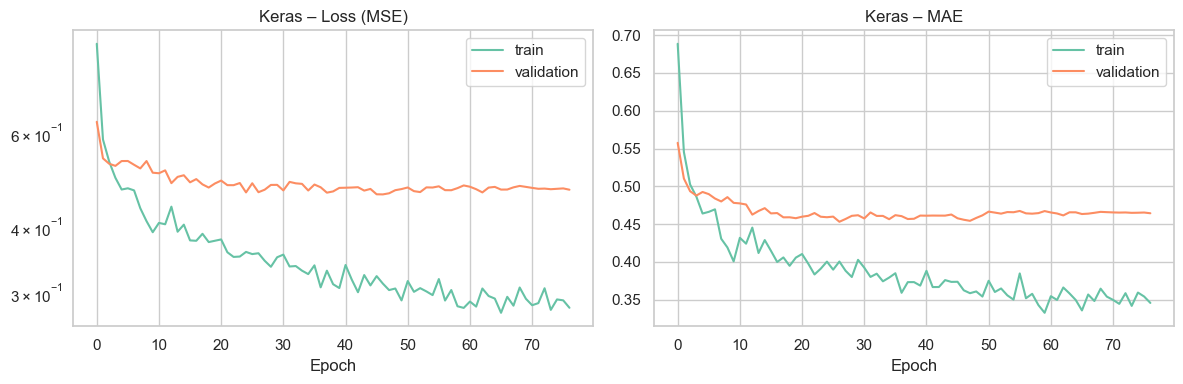

In [26]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5),
]
history = model.fit(X_train_p, y_train_s, validation_split=0.15,
                    epochs=500, batch_size=32, callbacks=callbacks, verbose=0)
print("Epochs effectuées :", len(history.history["loss"]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Keras – Loss (MSE)"); ax[0].set_xlabel("Epoch"); ax[0].set_yscale("log"); ax[0].legend()
ax[1].plot(history.history["mae"], label="train"); ax[1].plot(history.history["val_mae"], label="validation")
ax[1].set_title("Keras – MAE"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

Modèle       TensorFlow / Keras
R² (log)               0.643108
R² (prix)              0.610172
RMSE             1403713.724779
MAE              1002248.759174
dtype: object


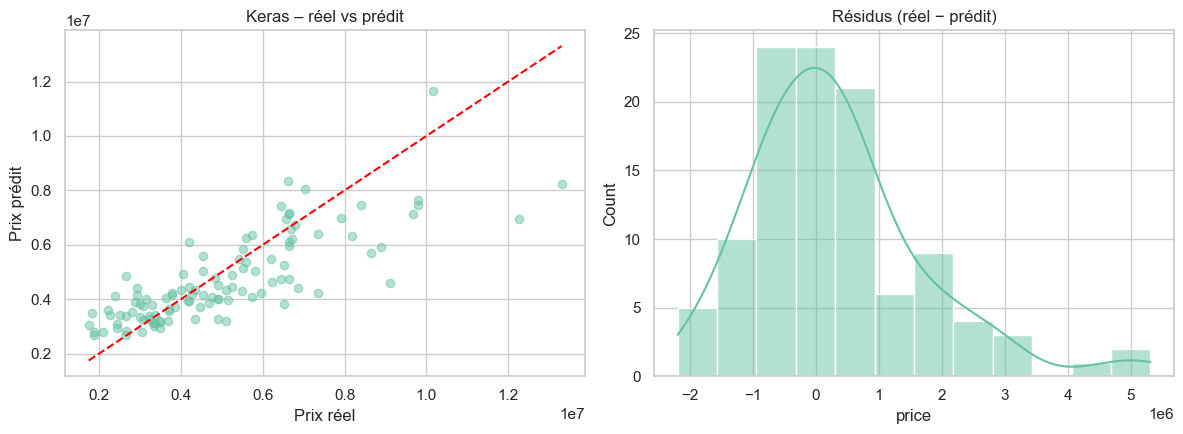

In [27]:
pred_keras = to_log(model.predict(X_test_p, verbose=0).ravel())
res_keras = evaluate("TensorFlow / Keras", y_test, pred_keras)
print(pd.Series(res_keras))
plot_pred(y_test, pred_keras, "Keras – réel vs prédit")

## 8. Comparaison des performances

,R² (log),R² (prix),RMSE,MAE
Modèle,,,,
sklearn MLPRegressor,0.6487,0.6380,"1,352,592","1,019,045"
TensorFlow GradientTape,0.5923,0.5714,"1,471,797","1,081,277"
TensorFlow / Keras,0.6431,0.6102,"1,403,714","1,002,249"


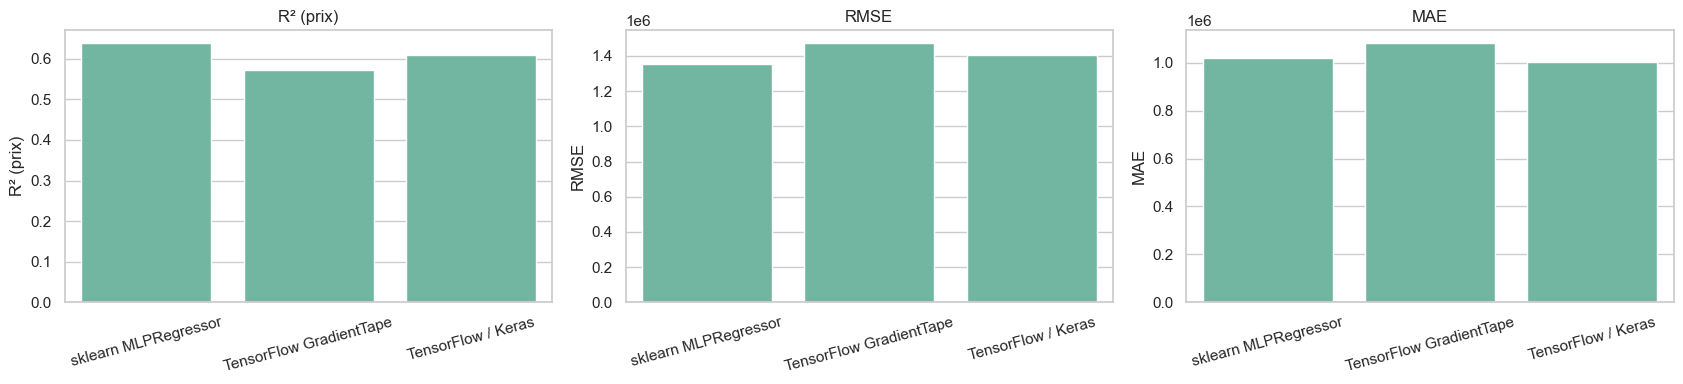

In [29]:
results = pd.DataFrame([res_mlp, res_gt, res_keras]).set_index("Modèle")
display(results.style.format({
    "R² (log)": "{:.4f}",
    "R² (prix)": "{:.4f}",
    "RMSE": "{:,.0f}",
    "MAE": "{:,.0f}"
}))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))

for a, m in zip(ax, ["R² (prix)", "RMSE", "MAE"]):
    sns.barplot(x=results.index, y=results[m], ax=a)
    a.tick_params(axis="x", rotation=15)
    a.set_title(m)
    a.set_xlabel("")

plt.tight_layout()
plt.show()


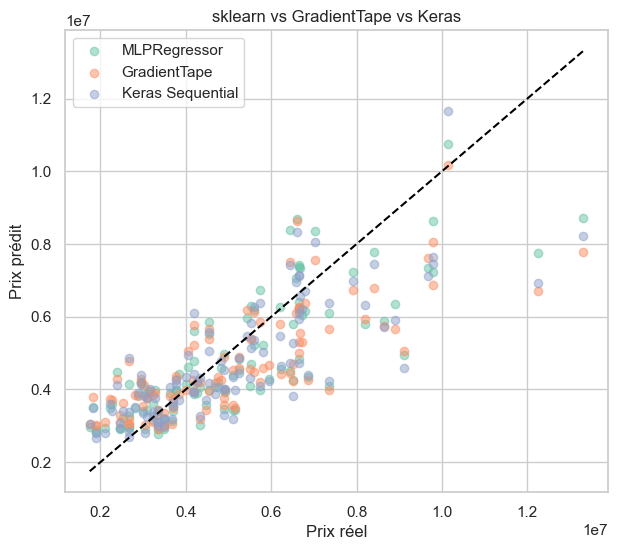

In [30]:
# Comparaison visuelle des trois modèles
yt = np.expm1(y_test)

plt.figure(figsize=(7, 6))
plt.scatter(yt, np.expm1(pred_mlp), alpha=.5, label="MLPRegressor")
plt.scatter(yt, np.expm1(pred_gt), alpha=.5, label="GradientTape")
plt.scatter(yt, np.expm1(pred_keras), alpha=.5, label="Keras Sequential")

plt.plot([yt.min(), yt.max()], [yt.min(), yt.max()], "k--")
plt.xlabel("Prix réel")
plt.ylabel("Prix prédit")
plt.legend()
plt.title("sklearn vs GradientTape vs Keras")
plt.show()


## Conclusion

- La base `Housing.csv` contient **545 observations et 13 variables**.
- `price` est la variable cible.
- Les variables catégorielles (`yes/no` et `furnishingstatus`) sont transformées par One-Hot Encoding.
- Les variables numériques sont imputées et standardisées.
- Les trois réseaux (`MLPRegressor`, `GradientTape`, `Keras Sequential`) utilisent les mêmes données prétraitées, ce qui permet une comparaison cohérente.
- La cible est transformée en `log1p(price)`, standardisée pour l'entraînement, puis reconvertie (inverse du scaler puis `expm1`) pour calculer RMSE et MAE dans l'unité du prix.

> **Remarque :** les cellules TensorFlow/Keras nécessitent TensorFlow installé dans l'environnement du notebook.
